# Shared dilated CNN: executed results and evidence

This notebook **reads and checks completed training and evaluation artifacts**. Training ran separately through `python -m cnn_improvement.train train`; its original epoch logs remain in `runs/`. Executing this notebook does not retrain the model.

**Disclosure:** AI-assisted implementation and execution. The agreed comparison uses the single seed-42 CNN as Stage 1 and the three-seed ensemble as Stage 2. Stage 1 has validation results; its separate test evaluation is still pending. This evidence report is not yet the complete two-stage submission notebook.

In [1]:
from pathlib import Path
import hashlib, json, sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'model.py').exists():
    ROOT = ROOT / 'cnn_improvement'
RESULTS = (ROOT / 'results').resolve()
read_json = lambda path: json.loads(path.read_text(encoding='utf-8'))
read_jsonl = lambda path: [json.loads(line) for line in path.read_text(encoding='utf-8').splitlines() if line.strip()]
results = read_json(RESULTS / 'results.json')
selection = read_json(RESULTS / 'selection.json')
assert hashlib.sha256((RESULTS / 'selection.json').read_bytes()).hexdigest() == results['selection_sha256']
assert results['reload_verified'] and results['parameters']['total'] <= 20_000_000
print('Report kernel:', sys.executable)
print('Training environment:')
print(json.dumps(results['environment'], indent=2))
print('Frozen selection:', selection['frozen_at_utc'])
print('Final evaluation:', results['evaluated_at_utc'])

Report kernel: C:\Users\samuel\anaconda3\python.exe
Training environment:
{
  "python": "3.12.0 | packaged by Anaconda, Inc. | (main, Oct  2 2023, 17:20:38) [MSC v.1916 64 bit (AMD64)]",
  "executable": "C:\\Users\\samuel\\anaconda3\\envs\\env\\python.exe",
  "torch": "2.12.0+cpu",
  "numpy": "2.4.4",
  "platform": "Windows-11-10.0.26200-SP0",
  "processor": "AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD",
  "device": "cpu",
  "threads": 4,
  "gpu": null
}
Frozen selection: 2026-10-26T13:52:00.189172+00:00
Final evaluation: 2026-10-26T13:52:16.836986+00:00


## Data provenance and configuration

Only official MASSIVE 1.0 English training examples fit model parameters and vocabularies. The pretrained component is a GloVe word-vector table; the CNN, character encoder and output heads start from random weights. Both output heads share the word-sequence encoder. All parameters, including embeddings, count toward the cap.

In [2]:
manifest = read_json(ROOT / 'asset_manifest.json')
print(json.dumps(manifest, indent=2))
run_paths = []
for saved_path in selection['run_dirs']:
    path = Path(saved_path)
    if not path.exists():
        path = ROOT / 'runs' / saved_path.replace('\\', '/').split('/')[-1]
    run_paths.append(path)
setups = [read_json(path / 'setup.json') for path in run_paths]
summaries = [read_json(path / 'summary.json') for path in run_paths]
print('Recorded model/training configuration:')
print(json.dumps(setups[0]['config'], indent=2))
print('Training vocabulary:', setups[0]['vocab_words'], 'words;', setups[0]['vocab_chars'], 'characters')
print('Receptive field:', setups[0]['receptive_field_tokens'], 'tokens')
print('Maximum training utterance:', setups[0]['max_training_tokens'], 'tokens')
print('Embedding coverage:', json.dumps(setups[0]['embedding_coverage'], indent=2))

{
  "massive": {
    "path": "C:\\Users\\samuel\\OneDrive\\Desktop\\School Stuff\\Y4S1\\SC4002 Natural Language Processing\\Project\\cnn_improvement\\data\\en-US.jsonl",
    "source_url": "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz",
    "archive_member": "1.0/data/en-US.jsonl",
    "bytes": 3904197,
    "sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e",
    "split_counts": {
      "test": 2974,
      "train": 11514,
      "dev": 2033
    }
  },
  "glove": {
    "path": "C:\\Users\\samuel\\OneDrive\\Desktop\\School Stuff\\Y4S1\\SC4002 Natural Language Processing\\Project\\cnn_improvement\\embeddings\\glove.6B.300d.txt",
    "source_url": "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip",
    "archive_member": "glove.6B.300d.txt",
    "bytes": 1037965801,
    "sha256": "a12599d41e3589c7160be27fffe5b0080eccd0f0c75f46666c59f90188093c40",
    "project_url": "https://nlp.stanford.edu/projects/glove/",
 

## Correctness evidence

The diagnostic subset scores below check implementation wiring; they are not validation or test performance. Gold-label round trips check preprocessing, not generalisation.

In [3]:
diagnostics = ROOT / 'diagnostics'
preprocessing = read_json(diagnostics / 'preprocessing_validation.json')
sanity = read_json(diagnostics / 'sanity.json')
assert preprocessing['all_checks_passed'] and sanity['passed']
print('Preprocessing checks:')
print(json.dumps(preprocessing, indent=2))
print('Overfit sanity check:')
print(json.dumps({key: sanity[key] for key in ['purpose', 'n_training_examples', 'steps', 'final', 'passed']}, indent=2))
test_log = diagnostics / 'unit_tests.log'
if test_log.exists():
    raw = test_log.read_bytes()
    encoding = 'utf-16' if raw.startswith((b'\xff\xfe', b'\xfe\xff')) else 'utf-8-sig'
    print('Retained unit-test execution output:')
    print(raw.decode(encoding, errors='replace'))
else:
    print('No retained unit-test log was supplied; no test-run claim is inferred.')

Preprocessing checks:
{
  "data_sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e",
  "counts": {
    "train": 11514,
    "dev": 2033,
    "test": 2974
  },
  "training_inventory": {
    "words": 5304,
    "characters": 34,
    "intents": 60,
    "slot_types": 55,
    "bio_tags": 111
  },
  "reference": {
    "branch": "Max-Stage1",
    "commit": "41f96d0edf41f0ffefe8f6f7419d8cc085967b7b",
    "notebook_sha256": "0a069c5cf3fdadaed5dc60ffbf2b2e1748414f594c226b75b873b2c25e25a7f2",
    "executed_only": [
      "parse_gold_pairs",
      "tags_to_pairs",
      "evaluate"
    ]
  },
  "gold_roundtrip": {
    "train": {
      "n": 11514,
      "intent_correct": 11514,
      "tp": 11340,
      "fp": 0,
      "fn": 0,
      "intent_acc": 100.0,
      "slot_f1": 100.0,
      "combined": 100.0
    },
    "dev": {
      "n": 2033,
      "intent_correct": 2033,
      "tp": 2011,
      "fp": 0,
      "fn": 0,
      "intent_acc": 100.0,
      "slot_f1": 100.0,
      "combined

## Complete epoch histories

Every row below is read from a saved training log. Checkpoints were selected using the mean of validation intent accuracy and exact slot micro F1. Each seed's checkpoint was reloaded and its validation counts reproduced.

Seed 42: selected epoch 26; trained 35 epochs


,epoch,train_loss,dev_loss,dev_intent_acc,dev_slot_f1,dev_combined,epoch_seconds,elapsed_seconds
0,1,6.011275,2.593741,58.829316,52.614016,55.721666,8.999793,8.999796
1,2,2.359069,1.618609,80.029513,69.494850,74.762182,8.652063,17.690537
2,3,1.768602,1.450548,83.030005,74.476570,78.753288,8.625372,26.351365
3,4,1.548623,1.387220,84.210526,75.448513,79.829520,8.635547,35.023283
4,5,1.389099,1.360675,84.702410,78.012048,81.357229,8.564402,43.621102
5,6,1.295254,1.300255,85.341859,78.677769,82.009814,8.625911,52.281745
6,7,1.211506,1.316044,84.800787,78.151683,81.476235,8.703127,61.019395
7,8,1.151005,1.289333,85.981308,78.385739,82.183524,8.612972,69.652685
8,9,1.097196,1.295809,85.981308,78.834280,82.407794,8.608782,78.297386
9,10,1.048272,1.292871,85.735366,79.621796,82.678581,8.701122,87.033964


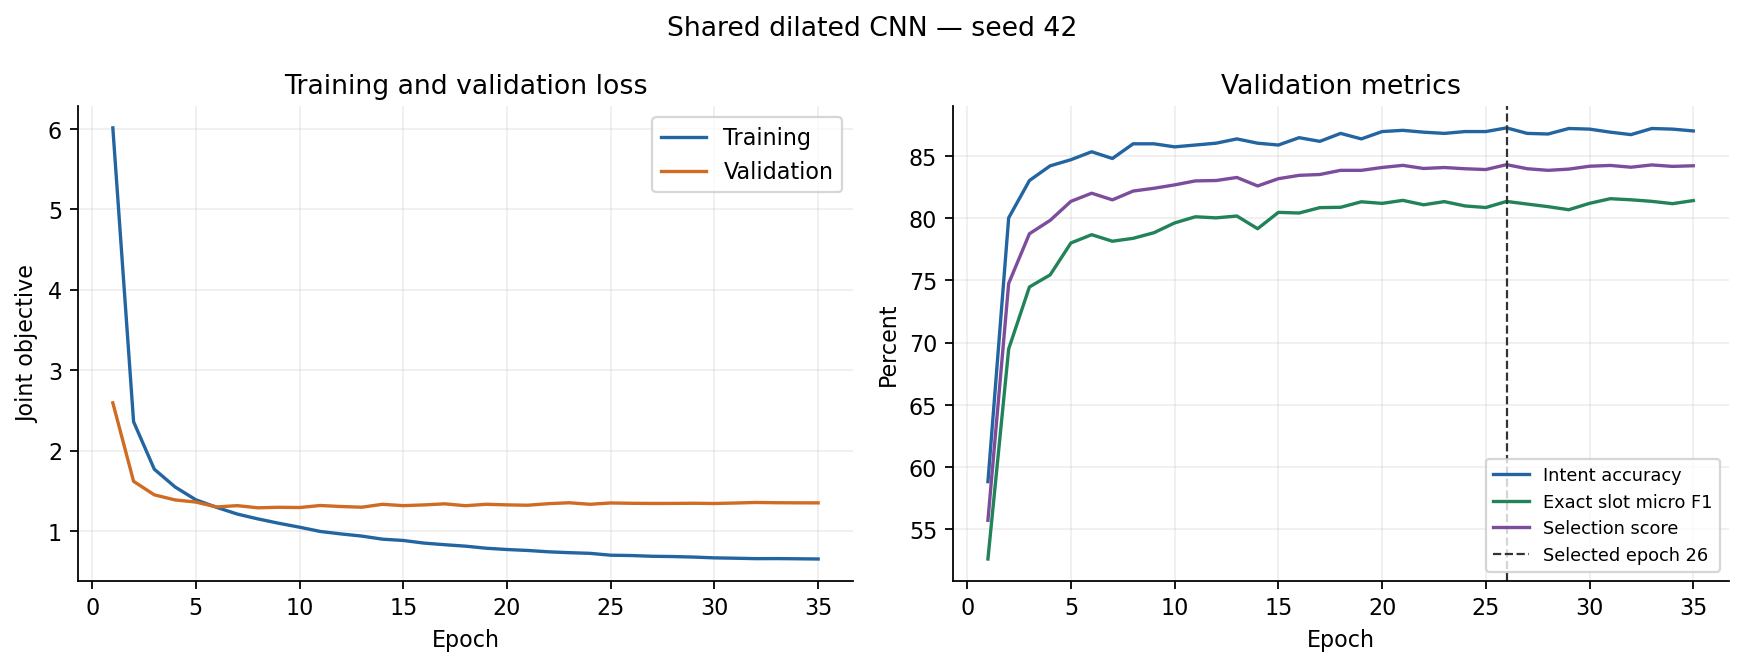

Seed 43: selected epoch 17; trained 26 epochs


,epoch,train_loss,dev_loss,dev_intent_acc,dev_slot_f1,dev_combined,epoch_seconds,elapsed_seconds
0,1,5.909321,2.684072,55.632071,50.740174,53.186122,9.604502,9.604505
1,2,2.396996,1.612808,80.177078,69.244288,74.710683,9.849032,19.493993
2,3,1.768820,1.447231,82.833251,74.511743,78.672497,9.830562,29.368336
3,4,1.514525,1.379225,84.456468,75.946827,80.201648,9.826802,39.236286
4,5,1.392248,1.346629,85.095917,77.688036,81.391977,9.795800,49.072785
5,6,1.293285,1.327290,84.702410,77.775006,81.238708,9.830589,58.943606
6,7,1.210154,1.322661,84.899164,78.619655,81.759409,9.715707,68.683717
7,8,1.145374,1.318715,85.046729,78.354554,81.700642,9.730562,78.455579
8,9,1.081625,1.313145,85.686178,79.769942,82.728060,10.088626,88.566606
9,10,1.035691,1.308605,85.833743,79.841897,82.837820,10.080769,98.690093


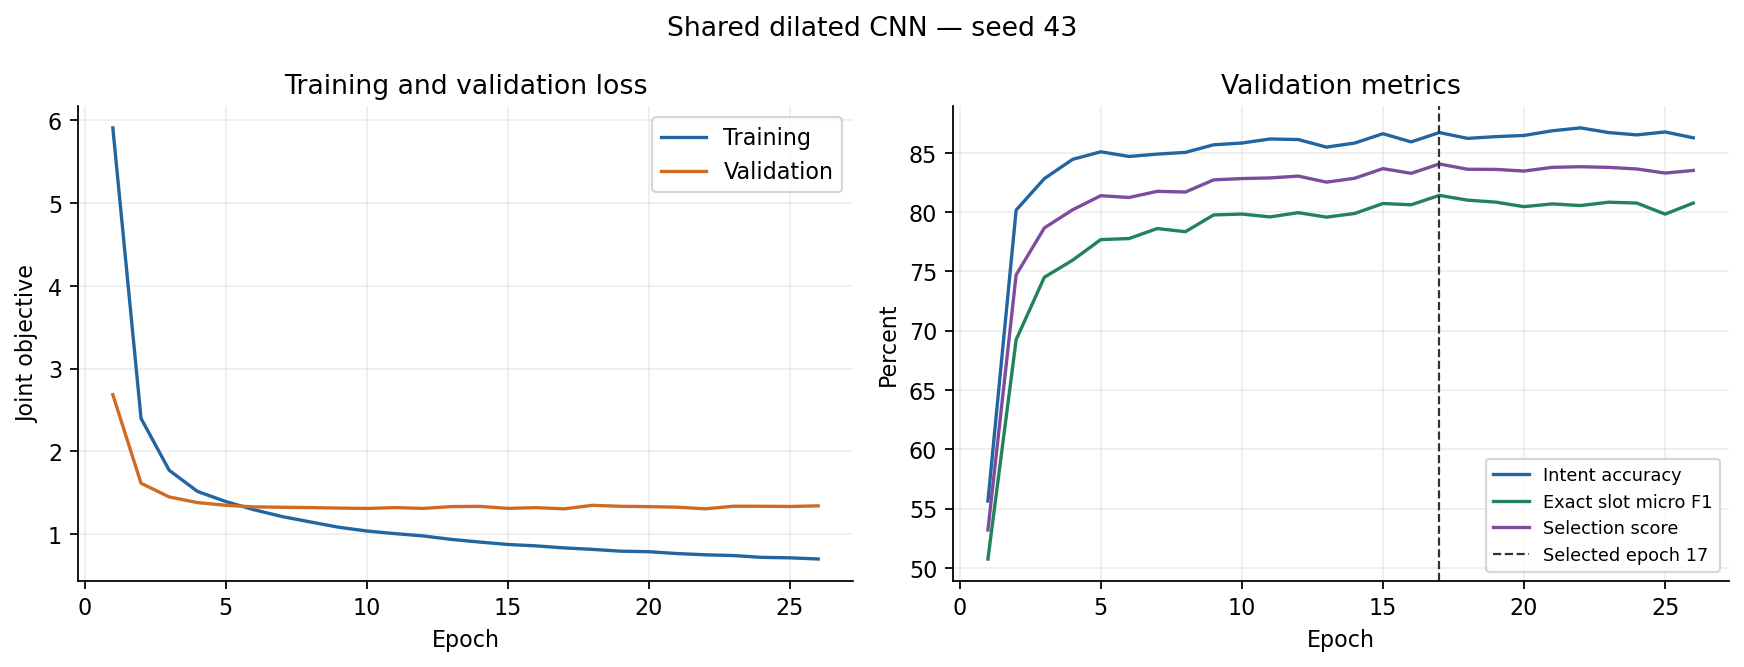

Seed 44: selected epoch 33; trained 36 epochs


,epoch,train_loss,dev_loss,dev_intent_acc,dev_slot_f1,dev_combined,epoch_seconds,elapsed_seconds
0,1,5.917386,2.588173,59.665519,50.287026,54.976273,10.185602,10.185605
1,2,2.370446,1.651726,77.963601,70.475252,74.219426,9.849931,20.077944
2,3,1.762325,1.466955,82.488933,73.676132,78.082532,9.866533,29.985878
3,4,1.533108,1.399878,83.423512,77.366255,80.394884,9.847690,39.871792
4,5,1.404816,1.369714,84.407280,76.282528,80.344904,9.663214,49.572117
5,6,1.302372,1.346479,84.308903,77.334654,80.821779,9.653020,59.247012
6,7,1.219283,1.317240,85.686178,77.430470,81.558324,9.784949,69.072156
7,8,1.150797,1.328186,85.489424,77.104874,81.297149,9.999103,79.111721
8,9,1.087984,1.337504,85.735366,79.690619,82.712993,9.983375,89.116478
9,10,1.051259,1.303317,86.079685,78.293227,82.186456,9.885867,99.041621


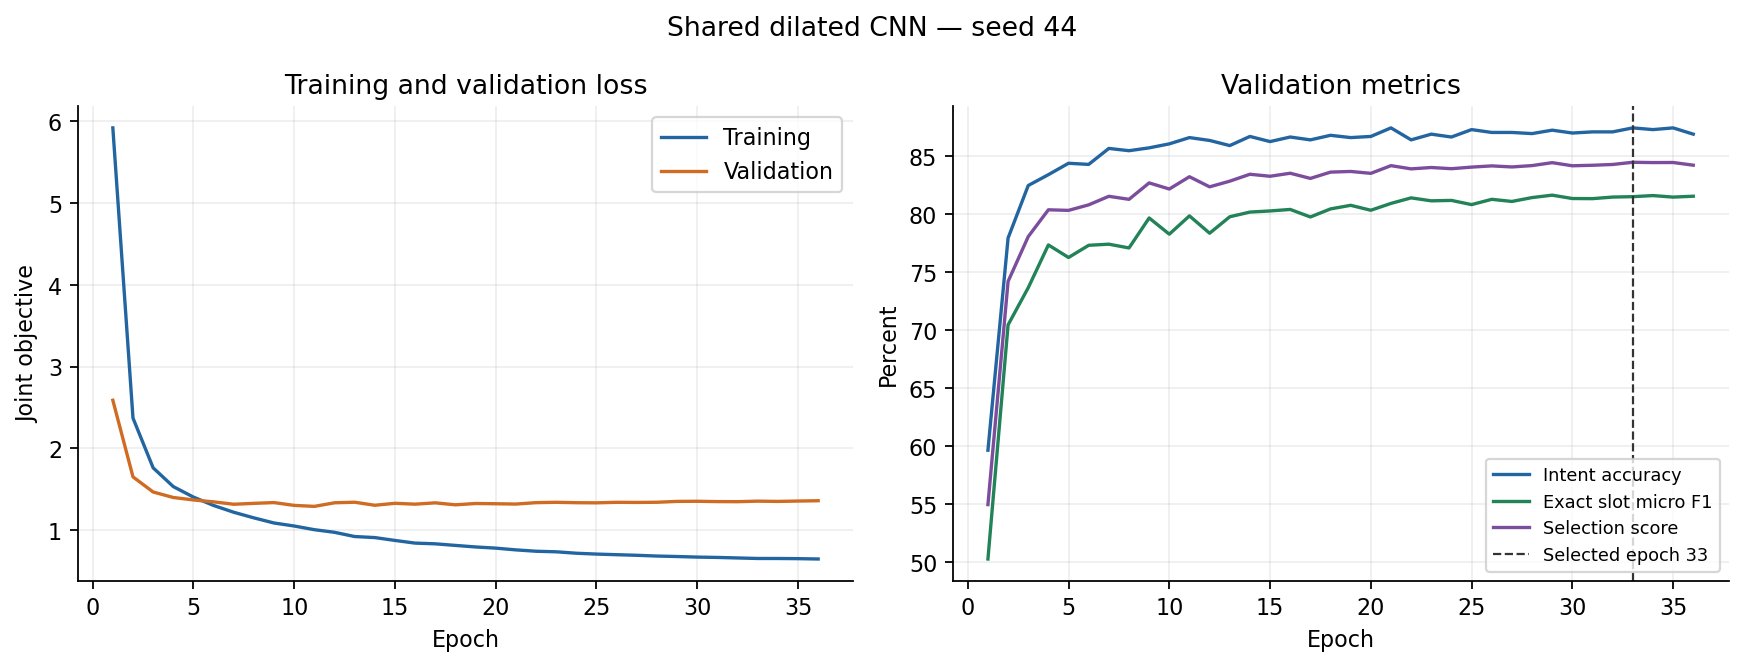

In [4]:
for path, summary in zip(run_paths, summaries):
    history = pd.DataFrame(read_jsonl(path / 'history.jsonl'))
    assert len(history) == summary['epochs_trained']
    best = history.loc[history['dev_combined'].idxmax()]
    assert int(best['epoch']) == summary['best_epoch']
    print(f"Seed {summary['seed']}: selected epoch {summary['best_epoch']}; trained {summary['epochs_trained']} epochs")
    display(history[['epoch', 'train_loss', 'dev_loss', 'dev_intent_acc', 'dev_slot_f1', 'dev_combined', 'epoch_seconds', 'elapsed_seconds']])
    display(Image(filename=str(RESULTS / f"learning_curves_seed{summary['seed']}.png")))

## Validation-only system selection

The prespecified candidates are the individual seed checkpoints and their full ensemble. The largest validation mean wins; an exact tie favours fewer parameters. The selected checkpoint hashes were frozen before evaluating test data.

In [5]:
candidate_rows = []
for candidate in selection['candidates']:
    metric = candidate['validation']
    candidate_rows.append({'candidate': candidate['name'], 'members': candidate['members'],
        'total_parameters': candidate['parameters']['total'], 'dev_intent_accuracy': metric['intent_acc'],
        'dev_exact_slot_f1': metric['slot_f1'], 'dev_combined': metric['combined']})
display(pd.DataFrame(candidate_rows).round(2))
print('Selected:', results['selected_candidate'])
print('Selection rule:', selection['selection_rule'])

,candidate,members,total_parameters,dev_intent_accuracy,dev_exact_slot_f1,dev_combined
0,member_0,[0],2307402,87.26,81.35,84.30
1,member_1,[1],2307402,86.72,81.42,84.07
2,member_2,[2],2307402,87.46,81.53,84.49
3,ensemble,"[0, 1, 2]",6922206,87.70,82.85,85.28


Selected: ensemble
Selection rule: maximum dev combined score; ties prefer fewer parameters


## Frozen validation and test results

Metrics are percentages. Slot micro F1 pools exact `(slot type, original span text)` set matches across utterances. Inference timing below includes local batching and decoding; it is not a controlled comparison with another architecture.

In [6]:
table = pd.read_csv(RESULTS / 'results.csv')
display(table[['split', 'total_parameters', 'trainable_parameters', 'intent_accuracy_percent',
               'exact_slot_micro_f1_percent', 'combined_percent', 'best_epochs', 'epochs_trained']])
for split in ['validation', 'test']:
    metric = results[split]
    assert abs(metric['intent_acc'] - 100 * metric['intent_correct'] / metric['n']) < 1e-10
    denom = 2 * metric['tp'] + metric['fp'] + metric['fn']
    assert abs(metric['slot_f1'] - 100 * 2 * metric['tp'] / denom) < 1e-10
    print(split, json.dumps(metric, indent=2))
print('Sum of selected members’ recorded training-process elapsed times (seconds):',
      results['training_seconds_selected_members'])
print('This sum is not overall wall-clock time when runs execute concurrently.')
verification_path = RESULTS / 'verification.json'
if verification_path.exists():
    verification = read_json(verification_path)
    assert verification['exact_counts_reproduced']
    print('Independent frozen reload/evaluation reproduced all recorded integer counts.')

,split,total_parameters,trainable_parameters,intent_accuracy_percent,exact_slot_micro_f1_percent,combined_percent,best_epochs,epochs_trained
0,validation,6922206,6922206,87.70,82.85,85.28,26/17/33,35/26/36
1,test,6922206,6922206,87.59,80.96,84.28,26/17/33,35/26/36


validation {
  "n": 2033,
  "intent_correct": 1783,
  "tp": 1679,
  "fp": 363,
  "fn": 332,
  "intent_acc": 87.70290211510084,
  "slot_f1": 82.85220824080928,
  "combined": 85.27755517795507,
  "inference_seconds": 0.9741705999767873,
  "utterances_per_second": 2086.903464391599
}
test {
  "n": 2974,
  "intent_correct": 2605,
  "tp": 2258,
  "fp": 505,
  "fn": 557,
  "intent_acc": 87.59246805648958,
  "slot_f1": 80.96091789171746,
  "combined": 84.27669297410353,
  "inference_seconds": 1.6405536999809556,
  "utterances_per_second": 1812.8025922190318
}
Sum of selected members’ recorded training-process elapsed times (seconds): 923.6118203000224
This sum is not overall wall-clock time when runs execute concurrently.


## Two observed errors after finalisation

Examples are selected deterministically from saved predictions: the first validation slot mismatch and the first test intent mismatch, with a fallback if necessary. These are observations after model selection. They do not establish the cause of an error, and no tuning is performed in this notebook.

In [7]:
errors = read_json(RESULTS / 'error_examples.json')
for i, example in enumerate(errors, 1):
    print(f"Example {i}: {example['split']} ID {example['id']}")
    print('Utterance:', example['utt'])
    print('Gold intent:', example['gold_intent'])
    print('Predicted intent:', example['predicted_intent'])
    print('Gold slots:', example['gold_slots'])
    print('Predicted slots:', example['predicted_slots'])
    print('Missing slots:', example['missing_slots'])
    print('Unexpected slots:', example['unexpected_slots'])
    print('Selection:', example['selection_reason'])
    print(example['interpretation_limit'], '\n')

Example 1: dev ID 30
Utterance: cleaning is good dust is so bad do now your magic clean my carpet
Gold intent: iot_cleaning
Predicted intent: general_quirky
Gold slots: [['house_place', 'carpet']]
Predicted slots: []
Missing slots: [['house_place', 'carpet']]
Unexpected slots: []
Selection: First slot error in original dev order
Observed mismatch only; no causal diagnosis is established by this example. 

Example 2: test ID 8
Utterance: pink is all we need
Gold intent: iot_hue_lightchange
Predicted intent: play_music
Gold slots: [['color_type', 'pink']]
Predicted slots: [['artist_name', 'pink']]
Missing slots: [['color_type', 'pink']]
Unexpected slots: [['artist_name', 'pink']]
Selection: First intent error in original test order
Observed mismatch only; no causal diagnosis is established by this example. 



## Reproduce and inspect the implementation

Run the commands in [README.md](README.md). The implementation is in [model.py](model.py), [data.py](data.py), [metrics.py](metrics.py), [train.py](train.py), and [predict.py](predict.py). The source files remain editable and the original execution logs remain under `runs/`.

The experiment establishes measured performance for this implementation and configuration. It does not establish superiority over the existing repository baselines, whose training was not repeated under matched hardware and settings.

In [8]:
sources = []
for filename in ['model.py', 'data.py', 'metrics.py', 'train.py', 'predict.py']:
    path = ROOT / filename
    sources.append({'file': filename, 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
display(pd.DataFrame(sources))
print('Reproduction commands are in README.md; original runtime:', results['environment']['executable'])

,file,sha256
0,model.py,107048dcf8968d1769c2ff1f7f3f2b33ead98a0559165f...
1,data.py,959be8d41b152b138c62e5f07b3eac2cfd0c7fa01b82fe...
2,metrics.py,9c2f99be36589fbdf40388bddbcd34ecbc610f74974a21...
3,train.py,1d7863cba61fccecb1e43b861c2e9184857d20494b5fc6...
4,predict.py,bcc406f0e4ef75efefc553318ede176feb9b29c902b61a...


Reproduction commands are in README.md; original runtime: C:\Users\samuel\anaconda3\envs\env\python.exe
